# Exploratory Data Analysis — Betty player data

**Input:** `Data Science Task Data.xlsx - Result 1.csv` (100,000 rows × 77 columns)
**Outputs:** charts and `eda_report.txt` written to `eda_output/`

This notebook covers:
1. Data types and per-column profile
2. Missing values (table, bar chart, heatmap)
3. Descriptive statistics (numeric + categorical) and value counts
4. Distributions of all variables (histograms, log-scale, box plots, category bars, dates)
5. Pearson & Spearman correlations with heatmaps and scatter plots
6. Summary notes

Run all cells top-to-bottom. `log(...)` output is collected in `lines` and written to the text report at the end.


In [1]:
%matplotlib inline

import os
import textwrap
import warnings

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="talk")

CSV = "Data Science Task Data.xlsx - Result 1.csv"
OUT = "eda_output"
os.makedirs(OUT, exist_ok=True)

lines = []


def log(msg=""):
    print(msg)
    lines.append(str(msg))


def save(fig, name):
    """Save a figure to eda_output/ and render it in the notebook."""
    path = os.path.join(OUT, name)
    fig.savefig(path, dpi=120, bbox_inches="tight")
    log(f"[saved] {path}")
    display(fig)
    plt.close(fig)


## Load the data

In [2]:
df = pd.read_csv(CSV, low_memory=False)
n_rows, n_cols = df.shape

log("=" * 78)
log("EXPLORATORY DATA ANALYSIS")
log("=" * 78)
log(f"File: {CSV}")
log(f"Shape: {n_rows} rows x {n_cols} columns")
log("")


EXPLORATORY DATA ANALYSIS
File: Data Science Task Data.xlsx - Result 1.csv
Shape: 100000 rows x 77 columns



## 1. Data types

In [3]:
log("=" * 78)
log("1. DATA TYPES")
log("=" * 78)

dtype_summary = df.dtypes.value_counts().rename_axis("dtype").to_frame("n_columns")
log(dtype_summary.to_string())
log("")

dt = pd.DataFrame({
    "column": df.columns,
    "dtype": [str(t) for t in df.dtypes],
    "n_unique": [df[c].nunique(dropna=True) for c in df.columns],
    "n_missing": [df[c].isna().sum() for c in df.columns],
    "missing_pct": [round(df[c].isna().mean() * 100, 2) for c in df.columns],
})
log(dt.to_string(index=False))
log("")

# classify columns
numeric_cols = list(df.select_dtypes(include="number").columns)
bool_cols = list(dict.fromkeys(
    list(df.select_dtypes(include="boolean").columns) +
    list(df.select_dtypes(include="bool").columns)))
string_cols = list(df.select_dtypes(include=["object", "string"]).columns)


def looks_like_date(s):
    s = s.dropna().astype(str)
    if s.empty:
        return False
    return s.str.match(r"\d{4}-\d{2}-\d{2}").mean() > 0.9


date_cols = [c for c in string_cols if looks_like_date(df[c])]
categorical_cols = [c for c in df.columns
                    if c not in numeric_cols and c not in bool_cols and c not in date_cols]

# parse dates
for c in date_cols:
    df[c] = pd.to_datetime(df[c], errors="coerce")

log(f"Numeric columns ({len(numeric_cols)}): {numeric_cols}")
log(f"Boolean columns ({len(bool_cols)}): {bool_cols}")
log(f"Datetime columns ({len(date_cols)}): {date_cols}")
log(f"Categorical/object columns ({len(categorical_cols)})")
log("")


1. DATA TYPES
         n_columns
dtype             
str             48
float64         19
object           5
bool             3
int64            2



                    column   dtype  n_unique  n_missing  missing_pct
                 player_id   int64    100000          0         0.00
         registration_date     str     99999          0         0.00
               modified_at     str     99999          0         0.00
                 closed_at     str     17808      82192        82.19
                     email     str     99999          0         0.00
              phone_number   int64     96599          0         0.00
                    status     str         7          0         0.00
             status_reason     str     10486      66132        66.13
           is_test_account    bool         2          0         0.00
              gaming_level     str         2         17         0.02
           aml_risk_rating     str         4       2136         2.14
          tc_accepted_date     str     99998          0         0.00
                first_name     str     23660          0         0.00
               middle_name     str

Numeric columns (21): ['player_id', 'phone_number', 'employer_phone_number', 'referrer_player_id', 'vip_level', 'ad_group', 'ad_set', 'marketing_creative', 'marketing_keyword', 'marketing_network', 'ad_campaign_id', 'ad_group_id', 'ad_keyword_id', 'marketing_click_date', 'marketing_location', 'max_profit_segment_rank', 'total_deposits', 'total_withdrawals', 'total_bets', 'total_wins', 'total_logins']
Boolean columns (3): ['is_test_account', 'is_pep', 'has_sanctions']
Datetime columns (8): ['registration_date', 'modified_at', 'closed_at', 'tc_accepted_date', 'birth_date', 'loaded_at', 'vip_status_updated_at', 'first_deposit_day']
Categorical/object columns (45)



## 2. Missing values

2. MISSING VALUES


                            n_missing  pct_missing  n_present
marketing_network              100000       100.00          0
marketing_location             100000       100.00          0
adfcd                           99995       100.00          5
marketing_click_date           100000       100.00          0
d_click_id                      99996       100.00          4
ad_set                         100000       100.00          0
marketing_creative             100000       100.00          0
marketing_keyword              100000       100.00          0
ad_group                       100000       100.00          0
btag                            99997       100.00          3
player_vip_account_manager      99733        99.73        267
employer_phone_number           99696        99.70        304
vip_status_updated_at           99642        99.64        358
portfolio_vip_status            99642        99.64        358
tiktok_click_id                 99624        99.62        376
employer

Total missing cells: 3504001 (45.51% of all cells)



[saved] eda_output/missing_values.png


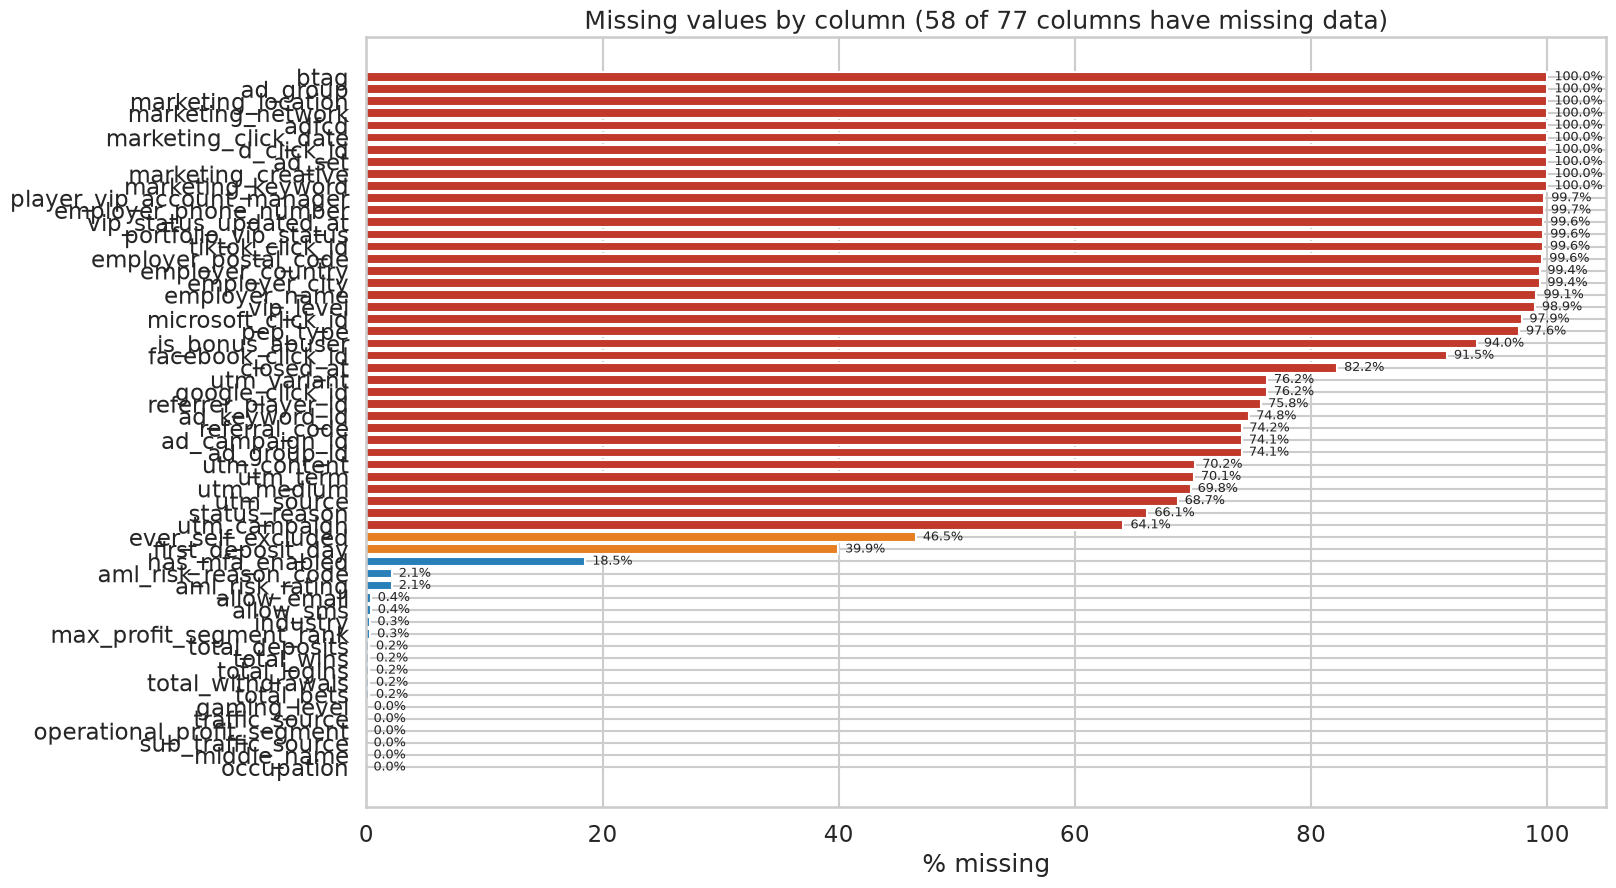

[saved] eda_output/missingness_heatmap.png


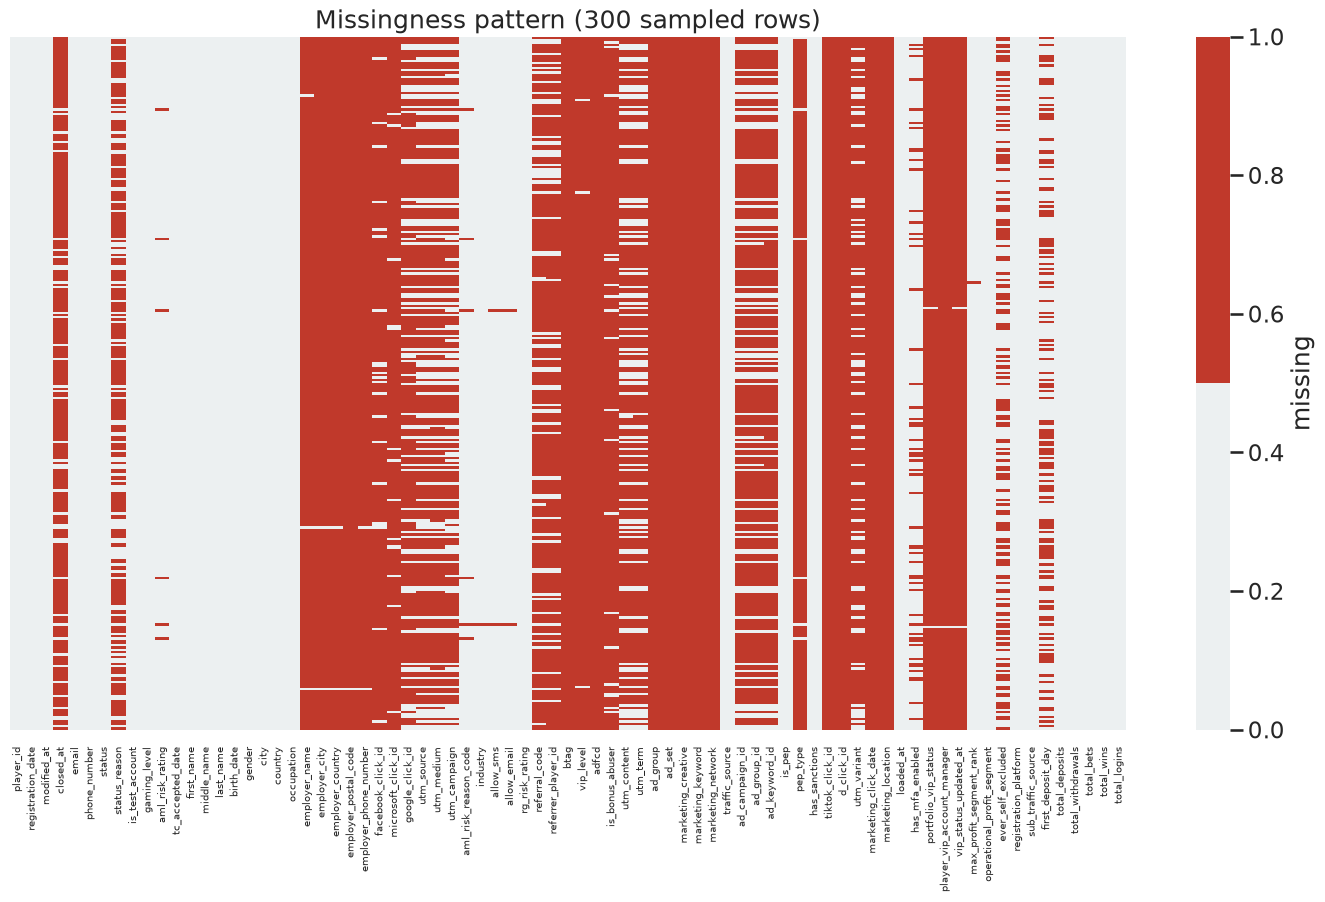

In [4]:
log("=" * 78)
log("2. MISSING VALUES")
log("=" * 78)

miss = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(2),
    "n_present": df.notna().sum(),
}).sort_values("pct_missing", ascending=False)
log(miss.to_string())
log("")
log(f"Columns with NO missing values: {(miss['n_missing'] == 0).sum()}")
log(f"Columns with ANY missing values: {(miss['n_missing'] > 0).sum()}")
log(f"Columns >90% missing: {(miss['pct_missing'] > 90).sum()}")
log(f"Total missing cells: {int(df.isna().sum().sum())} "
    f"({df.isna().mean().mean() * 100:.2f}% of all cells)")
log("")

# missingness bar chart
fig, ax = plt.subplots(figsize=(16, 10))
plot_miss = miss[miss["n_missing"] > 0].sort_values("pct_missing")
colors = ["#c0392b" if p > 50 else "#e67e22" if p > 20 else "#2980b9"
          for p in plot_miss["pct_missing"]]
ax.barh(plot_miss.index.astype(str), plot_miss["pct_missing"], color=colors)
ax.set_xlabel("% missing")
ax.set_title(f"Missing values by column ({len(plot_miss)} of {n_cols} columns have missing data)")
for i, (v, name) in enumerate(zip(plot_miss["pct_missing"], plot_miss.index.astype(str))):
    ax.text(v + 0.6, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, min(105, plot_miss["pct_missing"].max() * 1.15 + 3))
save(fig, "missing_values.png")

# missingness heatmap (sampled rows to keep it readable)
fig, ax = plt.subplots(figsize=(18, 9))
miss_mat = df.isna().astype(int)
sample_idx = np.linspace(0, n_rows - 1, min(300, n_rows)).astype(int)
sns.heatmap(miss_mat.iloc[sample_idx], cmap=["#ecf0f1", "#c0392b"],
            cbar_kws={"label": "missing"}, yticklabels=False, ax=ax)
ax.set_xticks(np.arange(0, n_cols, max(1, n_cols // 40)) + 0.5,
              labels=[c for c in df.columns][::max(1, n_cols // 40)],
              rotation=90, fontsize=7)
ax.set_title("Missingness pattern (300 sampled rows)")
save(fig, "missingness_heatmap.png")


## 3–4. Descriptive statistics

In [5]:
log("=" * 78)
log("3. DESCRIPTIVE STATISTICS - NUMERIC")
log("=" * 78)
log(df[numeric_cols].describe().T.to_string())
log("")
log("Skewness:")
log(df[numeric_cols].skew().sort_values(ascending=False).round(3).to_string())
log("")

log("=" * 78)
log("4. DESCRIPTIVE STATISTICS - CATEGORICAL")
log("=" * 78)
cat_desc = pd.DataFrame({
    "count": [df[c].notna().sum() for c in categorical_cols],
    "unique": [df[c].nunique(dropna=True) for c in categorical_cols],
    "top": [df[c].mode(dropna=True).iloc[0] if df[c].notna().any() else None
            for c in categorical_cols],
    "top_freq": [df[c].value_counts(dropna=True).iloc[0] if df[c].notna().any() else 0
                 for c in categorical_cols],
}, index=pd.Index(categorical_cols, name="column"))
log(cat_desc.to_string())
log("")

log("-" * 78)
log("Value counts for key low-cardinality categoricals")
log("-" * 78)
key_cats = [c for c in ["status", "status_reason", "gender", "gaming_level",
                        "aml_risk_rating", "rg_risk_rating", "country", "city",
                        "occupation", "industry", "allow_sms", "allow_email",
                        "is_test_account", "is_bonus_abuser", "is_pep",
                        "has_sanctions", "ever_self_excluded", "registration_platform",
                        "traffic_source", "sub_traffic_source", "utm_source",
                        "operational_profit_segment", "portfolio_vip_status",
                        "vip_status_updated_at", "max_profit_segment_rank",
                        "has_mfa_enabled", "marketing_network"]
            if c in df.columns]
for c in key_cats:
    vc = df[c].value_counts(dropna=False).head(15)
    log(f"\n{c} ({df[c].nunique(dropna=True)} unique):")
    for k, v in vc.items():
        log(f"    {repr(k):<45} {v:>7} ({v / n_rows * 100:5.2f}%)")
log("")


3. DESCRIPTIVE STATISTICS - NUMERIC
                            count          mean           std           min           25%           50%           75%           max
player_id                100000.0  5.429423e+06  3.123198e+06  2.530000e+02  2.728064e+06  5.442616e+06  8.146623e+06  1.080022e+07
phone_number             100000.0  9.398439e+10  6.839243e+10  1.042100e+04  7.081506e+10  9.329602e+10  1.101590e+11  1.522097e+13
employer_phone_number       304.0  1.194694e+11  9.215323e+10  9.435000e+03  7.436580e+10  1.043336e+11  1.372506e+11  1.043687e+12
referrer_player_id        24237.0  4.449339e+06  3.070451e+06  2.070000e+02  1.759431e+06  4.227561e+06  6.943585e+06  1.078990e+07
vip_level                  1057.0  1.000000e+00  0.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00  1.000000e+00
ad_group                      0.0           NaN           NaN           NaN           NaN           NaN           NaN           NaN
ad_set                        0.0       

                             count  unique                                                                                                                                                                                                                                                                                                         top  top_freq
column                                                                                                                                                                                                                                                                                                                                                          
email                       100000   99999                                                                                                                                                                                                                                                            

## 5. Distributions — numeric

5. DISTRIBUTIONS - NUMERIC


[saved] eda_output/numeric_distributions.png


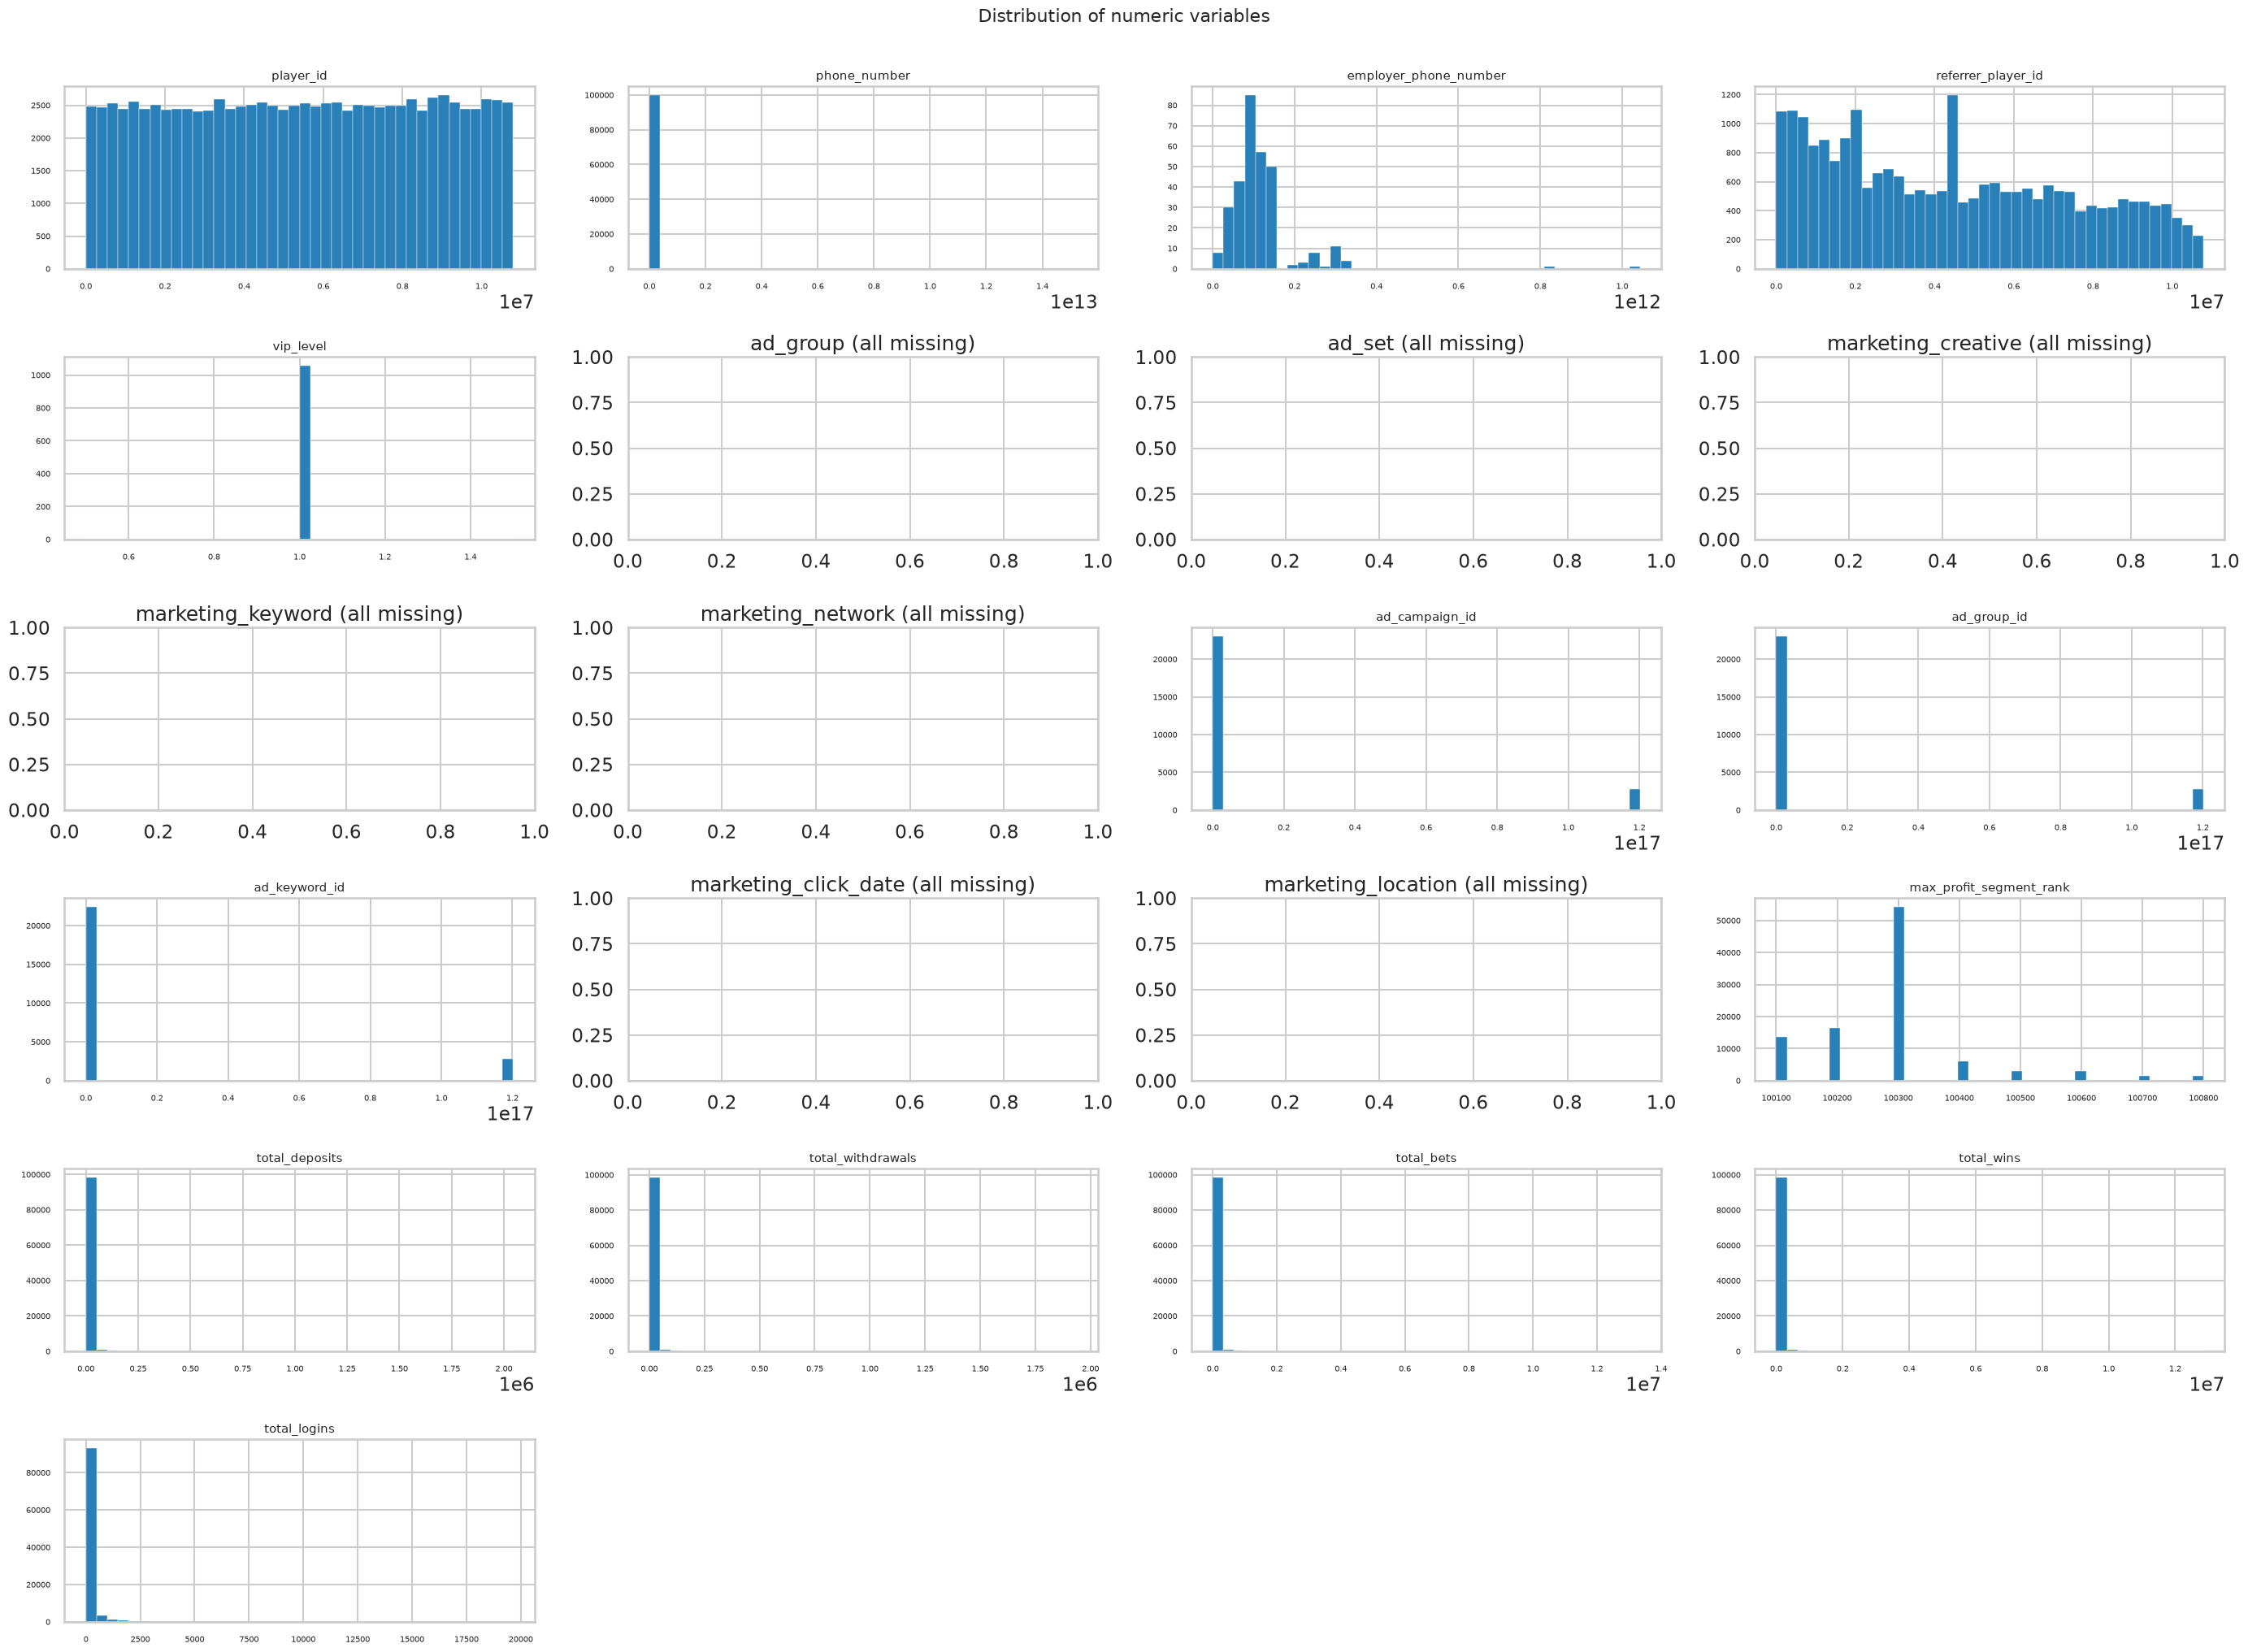

[saved] eda_output/numeric_distributions_log.png


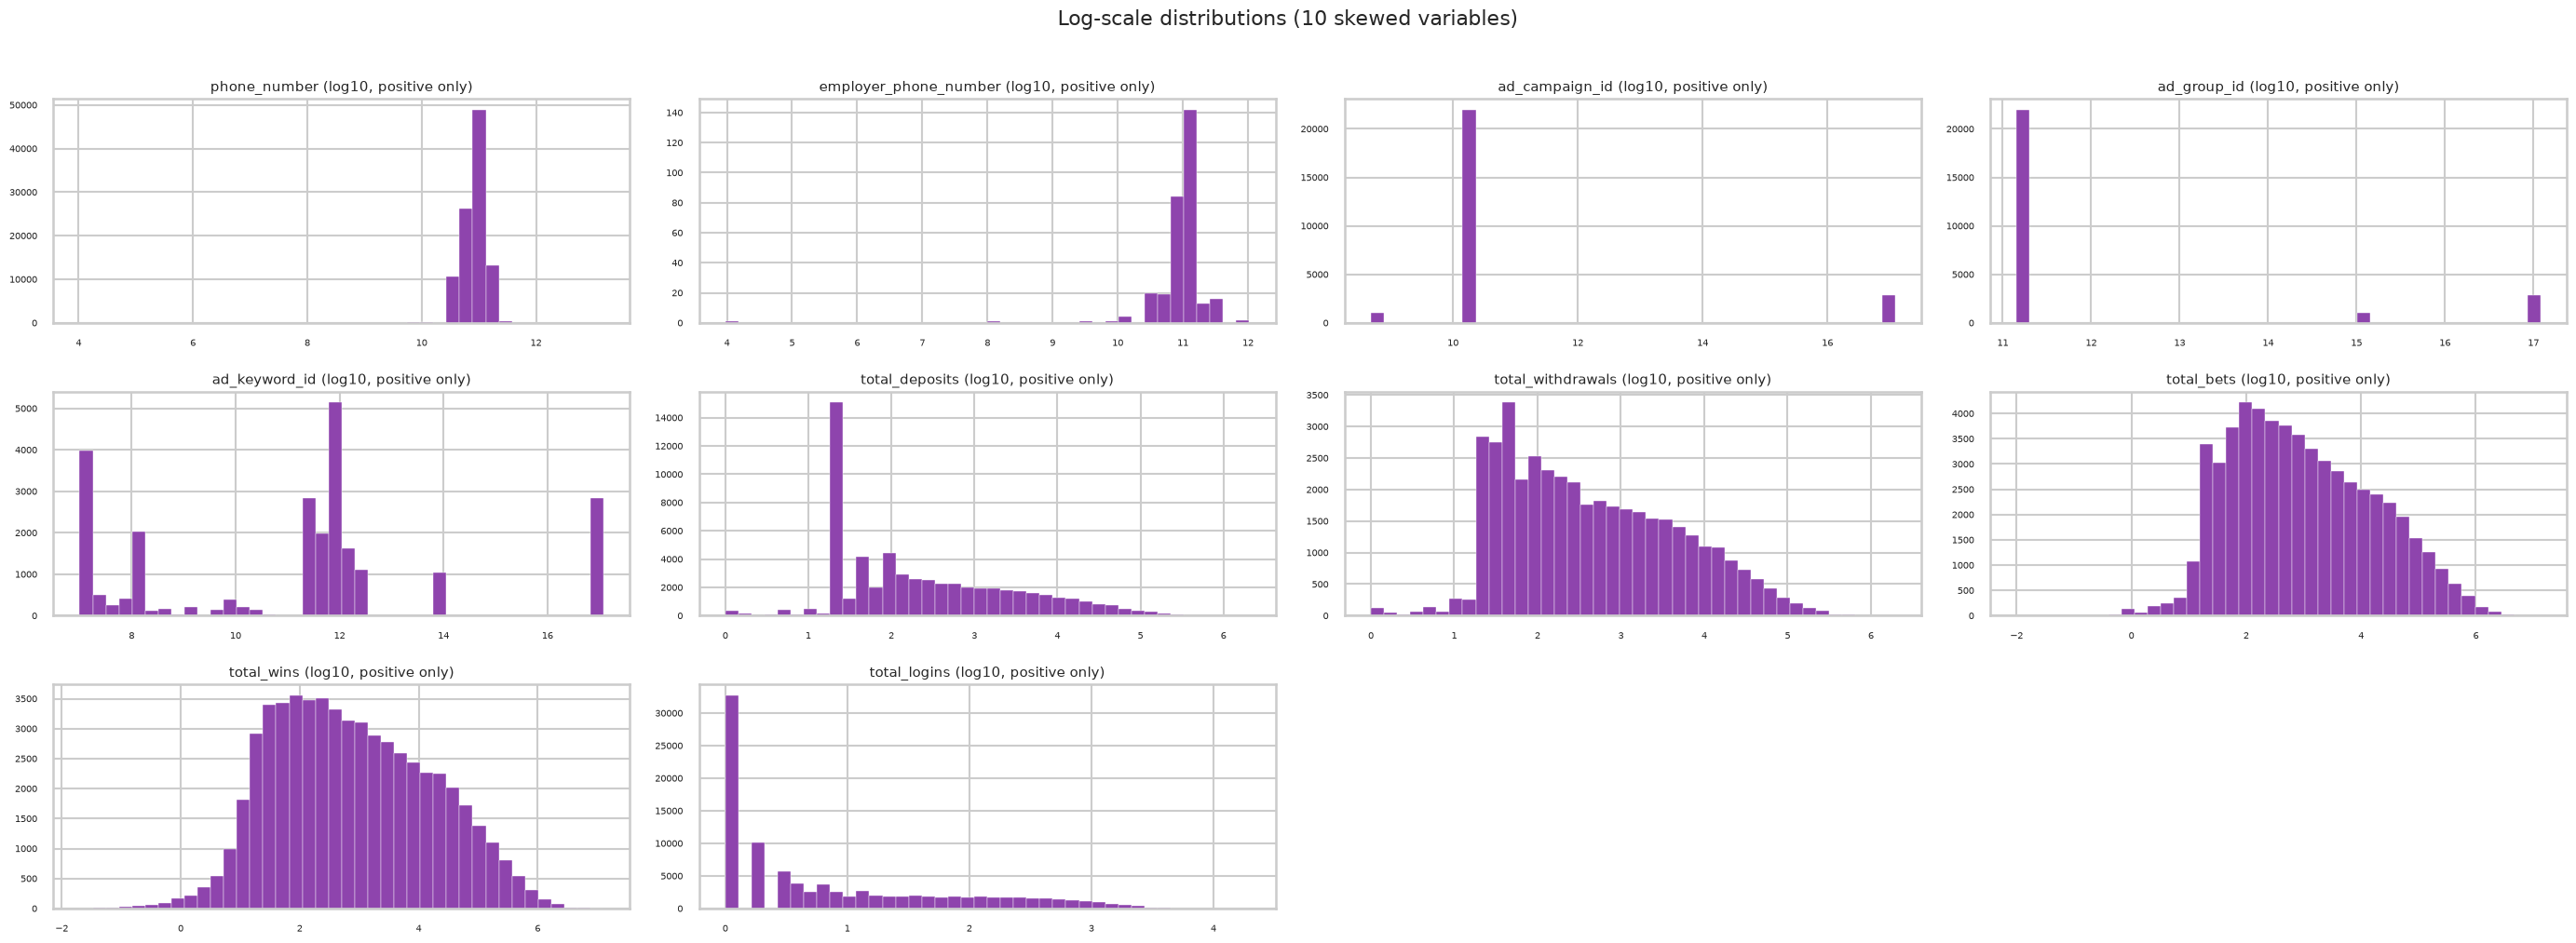

Skewed (|skew| > 2) numeric columns: ['phone_number', 'employer_phone_number', 'ad_campaign_id', 'ad_group_id', 'ad_keyword_id', 'total_deposits', 'total_withdrawals', 'total_bets', 'total_wins', 'total_logins']



[saved] eda_output/numeric_boxplots.png


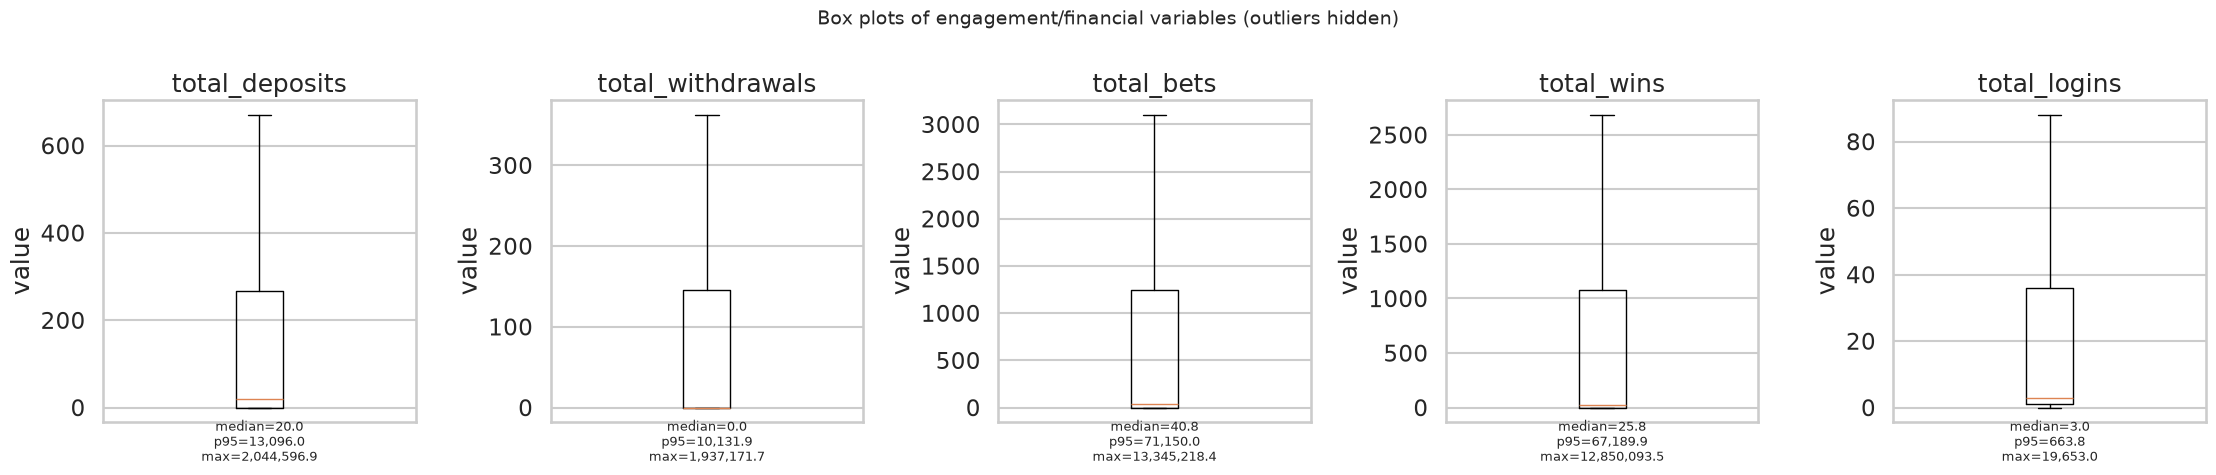

In [6]:
log("=" * 78)
log("5. DISTRIBUTIONS - NUMERIC")
log("=" * 78)

# histogram grid for all numeric columns
n = len(numeric_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 3.4 * nrows))
axes = np.array(axes).ravel()
for i, c in enumerate(numeric_cols):
    ax = axes[i]
    s = df[c].dropna()
    if s.empty:
        ax.set_title(f"{c} (all missing)")
        continue
    ax.hist(s, bins=40, color="#2980b9", edgecolor="white", linewidth=0.3)
    ax.set_title(f"{c}", fontsize=11)
    ax.tick_params(labelsize=7)
for j in range(i + 1, len(axes)):
    axes[j].axis("off")
fig.suptitle("Distribution of numeric variables", y=1.0, fontsize=16)
fig.tight_layout()
save(fig, "numeric_distributions.png")

# log-scale versions for heavily skewed money/count columns
skewed = [c for c in numeric_cols if abs(df[c].skew(skipna=True)) > 2]
if skewed:
    n = len(skewed)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 3.4 * nrows))
    axes = np.array(axes).ravel()
    for i, c in enumerate(skewed):
        ax = axes[i]
        s = df[c].dropna()
        s = s[s > 0]
        if s.empty:
            ax.set_title(f"{c} (no positive values)")
            continue
        ax.hist(np.log10(s), bins=40, color="#8e44ad", edgecolor="white", linewidth=0.3)
        ax.set_title(f"{c} (log10, positive only)", fontsize=11)
        ax.tick_params(labelsize=7)
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")
    fig.suptitle(f"Log-scale distributions ({n} skewed variables)", y=1.0, fontsize=16)
    fig.tight_layout()
    save(fig, "numeric_distributions_log.png")
log(f"Skewed (|skew| > 2) numeric columns: {skewed}")
log("")

# boxplots for key financial columns
money_cols = [c for c in ["total_deposits", "total_withdrawals", "total_bets",
                          "total_wins", "total_logins", "first_deposit_day"]
              if c in numeric_cols]
if money_cols:
    fig, axes = plt.subplots(1, len(money_cols), figsize=(4.5 * len(money_cols), 5))
    for ax, c in zip(np.atleast_1d(axes), money_cols):
        s = df[c].dropna()
        ax.boxplot(s, vert=True, showfliers=False)
        ax.set_title(c)
        ax.set_ylabel("value")
        med, p95 = s.median(), s.quantile(0.95)
        ax.set_xticks([])
        ax.text(0.5, -0.12, f"median={med:,.1f}\np95={p95:,.1f}\nmax={s.max():,.1f}",
                transform=ax.transAxes, ha="center", fontsize=9)
    fig.suptitle("Box plots of engagement/financial variables (outliers hidden)", fontsize=14)
    fig.tight_layout()
    save(fig, "numeric_boxplots.png")


## 6. Distributions — categorical

6. DISTRIBUTIONS - CATEGORICAL


Columns plotted as bar charts (2-25 unique values): ['status', 'gaming_level', 'aml_risk_rating', 'gender', 'country', 'aml_risk_reason_code', 'allow_sms', 'allow_email', 'rg_risk_rating', 'btag', 'adfcd', 'is_bonus_abuser', 'traffic_source', 'pep_type', 'd_click_id', 'has_mfa_enabled', 'portfolio_vip_status', 'player_vip_account_manager', 'operational_profit_segment', 'ever_self_excluded', 'registration_platform']


[saved] eda_output/categorical_distributions.png


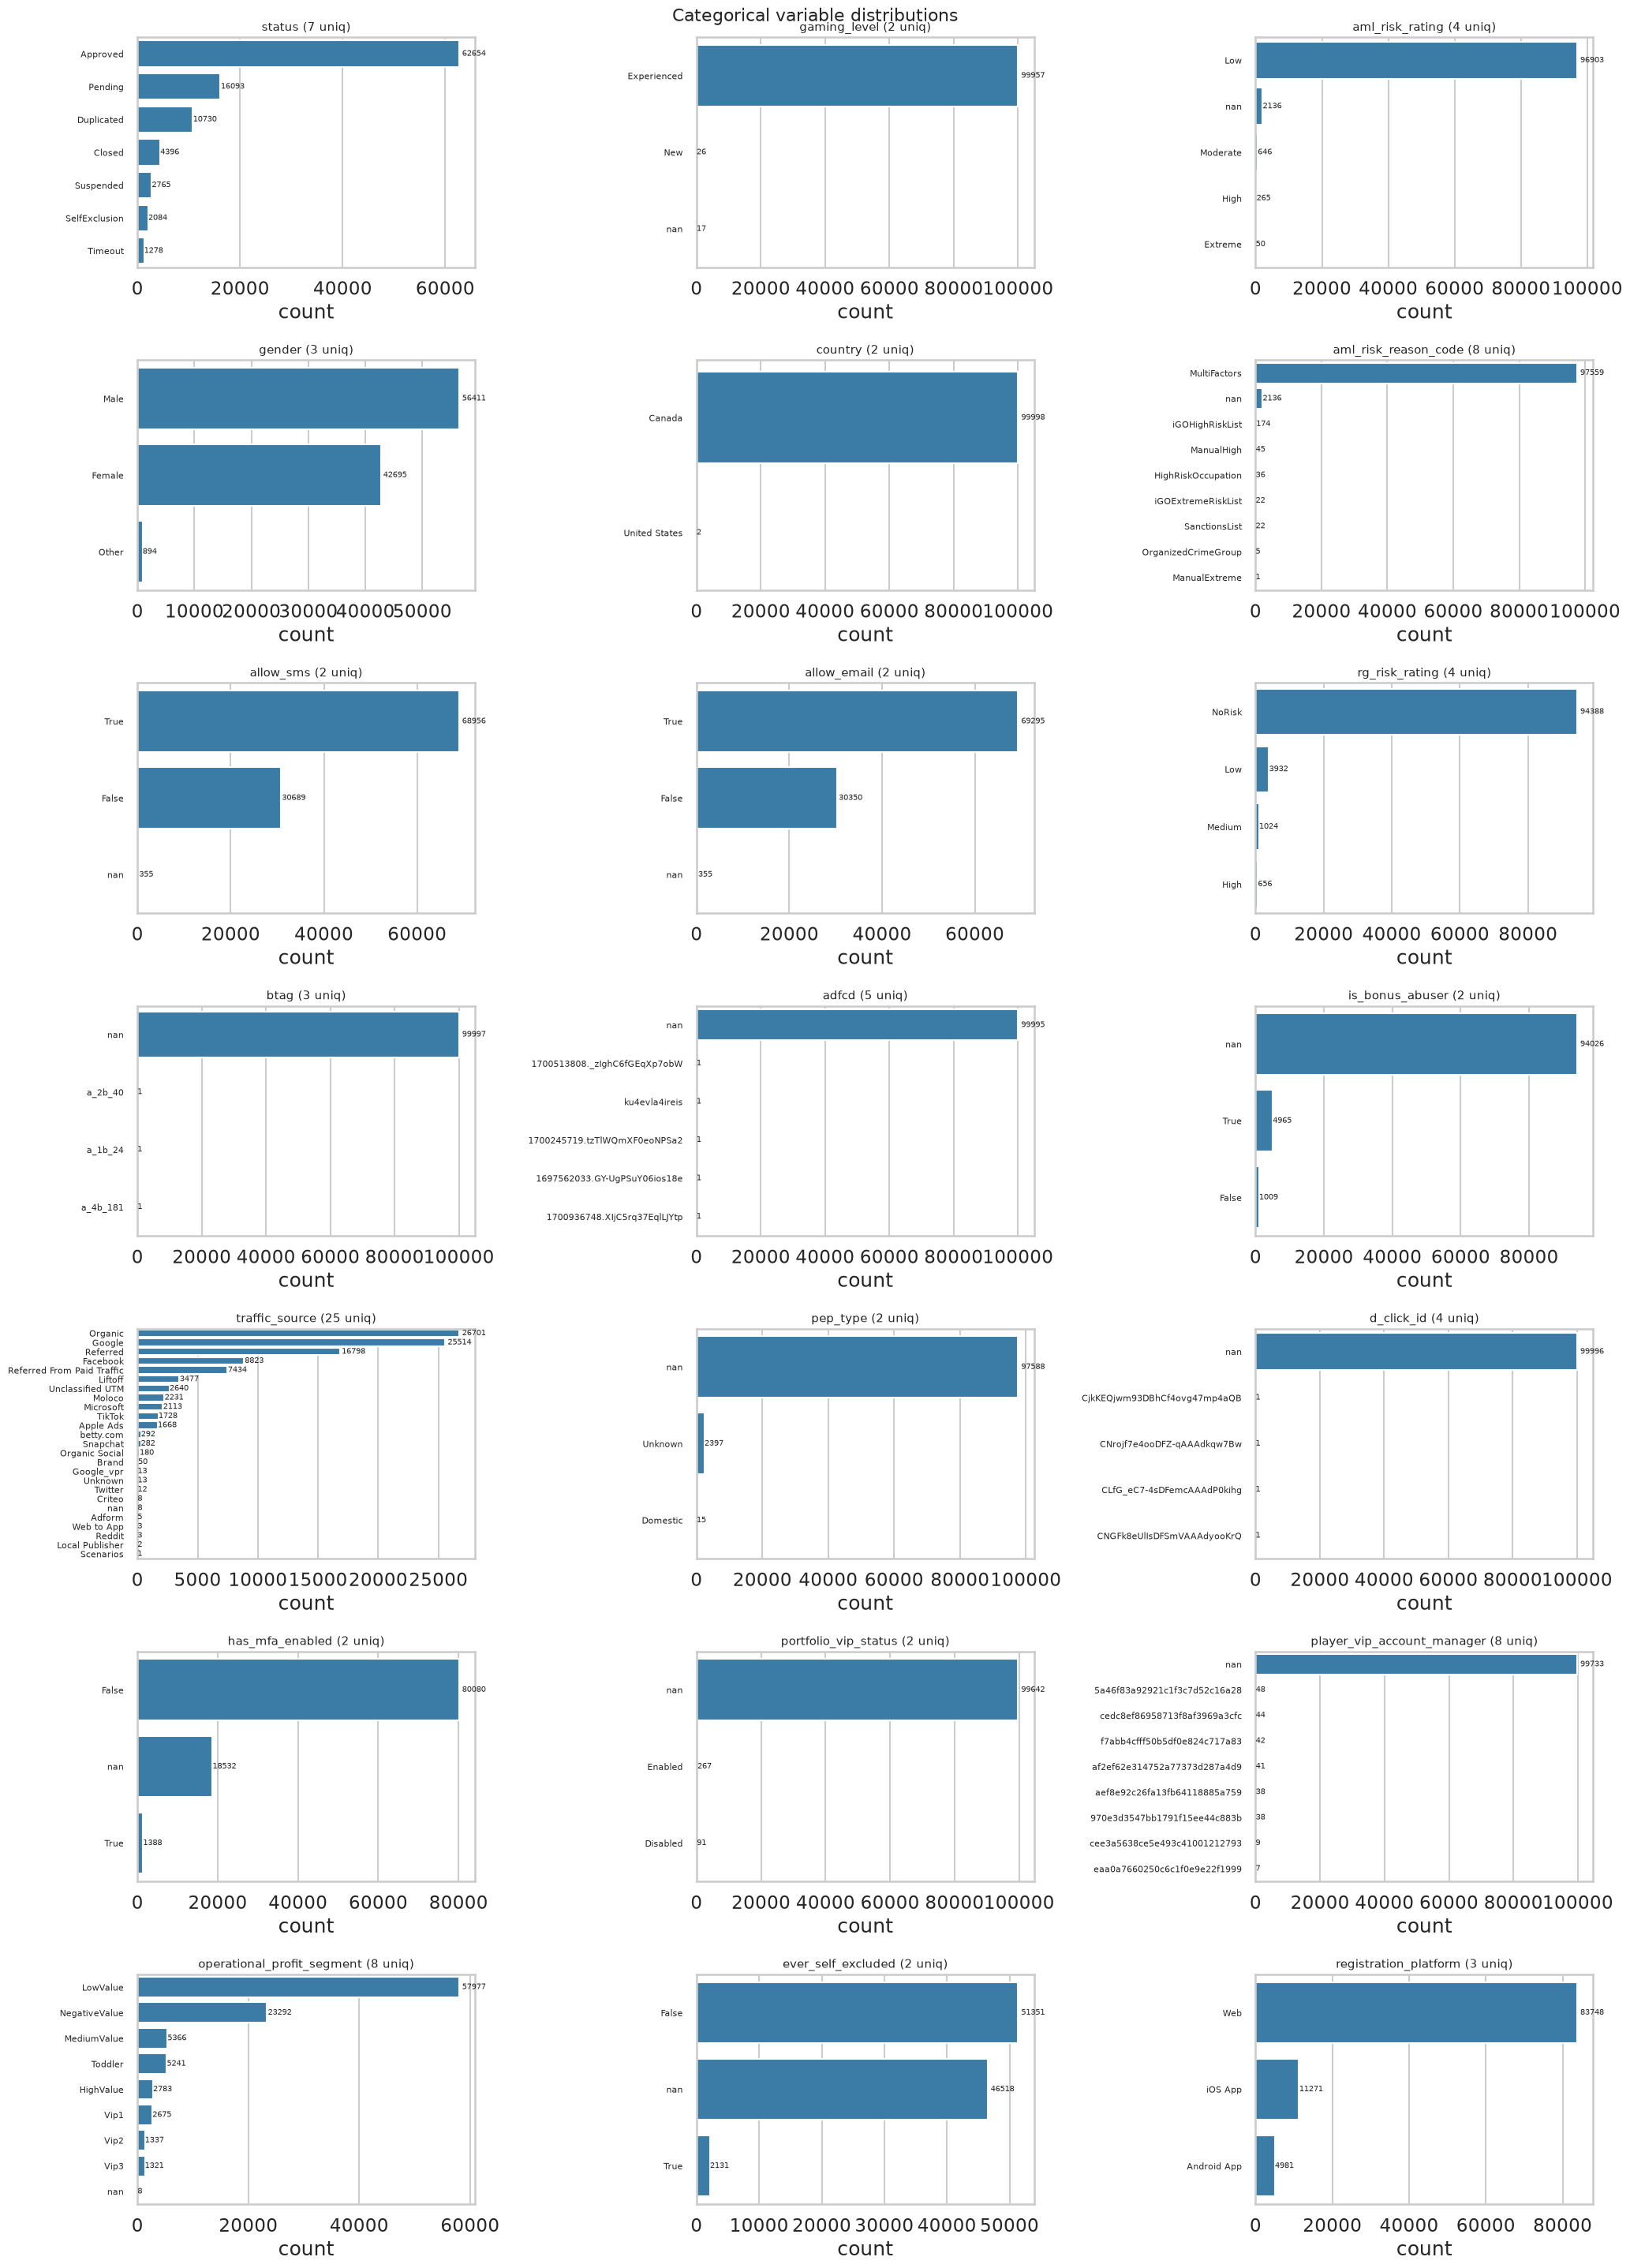


High-cardinality categorical columns (24):
    email: 99999 unique values, 0 missing
    status_reason: 10486 unique values, 66132 missing
    first_name: 23660 unique values, 0 missing
    middle_name: 6595 unique values, 4 missing
    last_name: 42517 unique values, 0 missing
    city: 3870 unique values, 0 missing
    occupation: 3642 unique values, 1 missing
    employer_name: 771 unique values, 99068 missing
    employer_city: 292 unique values, 99400 missing
    employer_country: 32 unique values, 99405 missing
    employer_postal_code: 432 unique values, 99560 missing
    facebook_click_id: 8496 unique values, 91489 missing
    microsoft_click_id: 2118 unique values, 97879 missing
    google_click_id: 23664 unique values, 76244 missing
    utm_source: 65 unique values, 68689 missing
    utm_medium: 653 unique values, 69792 missing
    utm_campaign: 1684 unique values, 64103 missing
    industry: 805 unique values, 331 missing
    referral_code: 22017 unique values, 74174 missin

[saved] eda_output/high_cardinality_top15.png


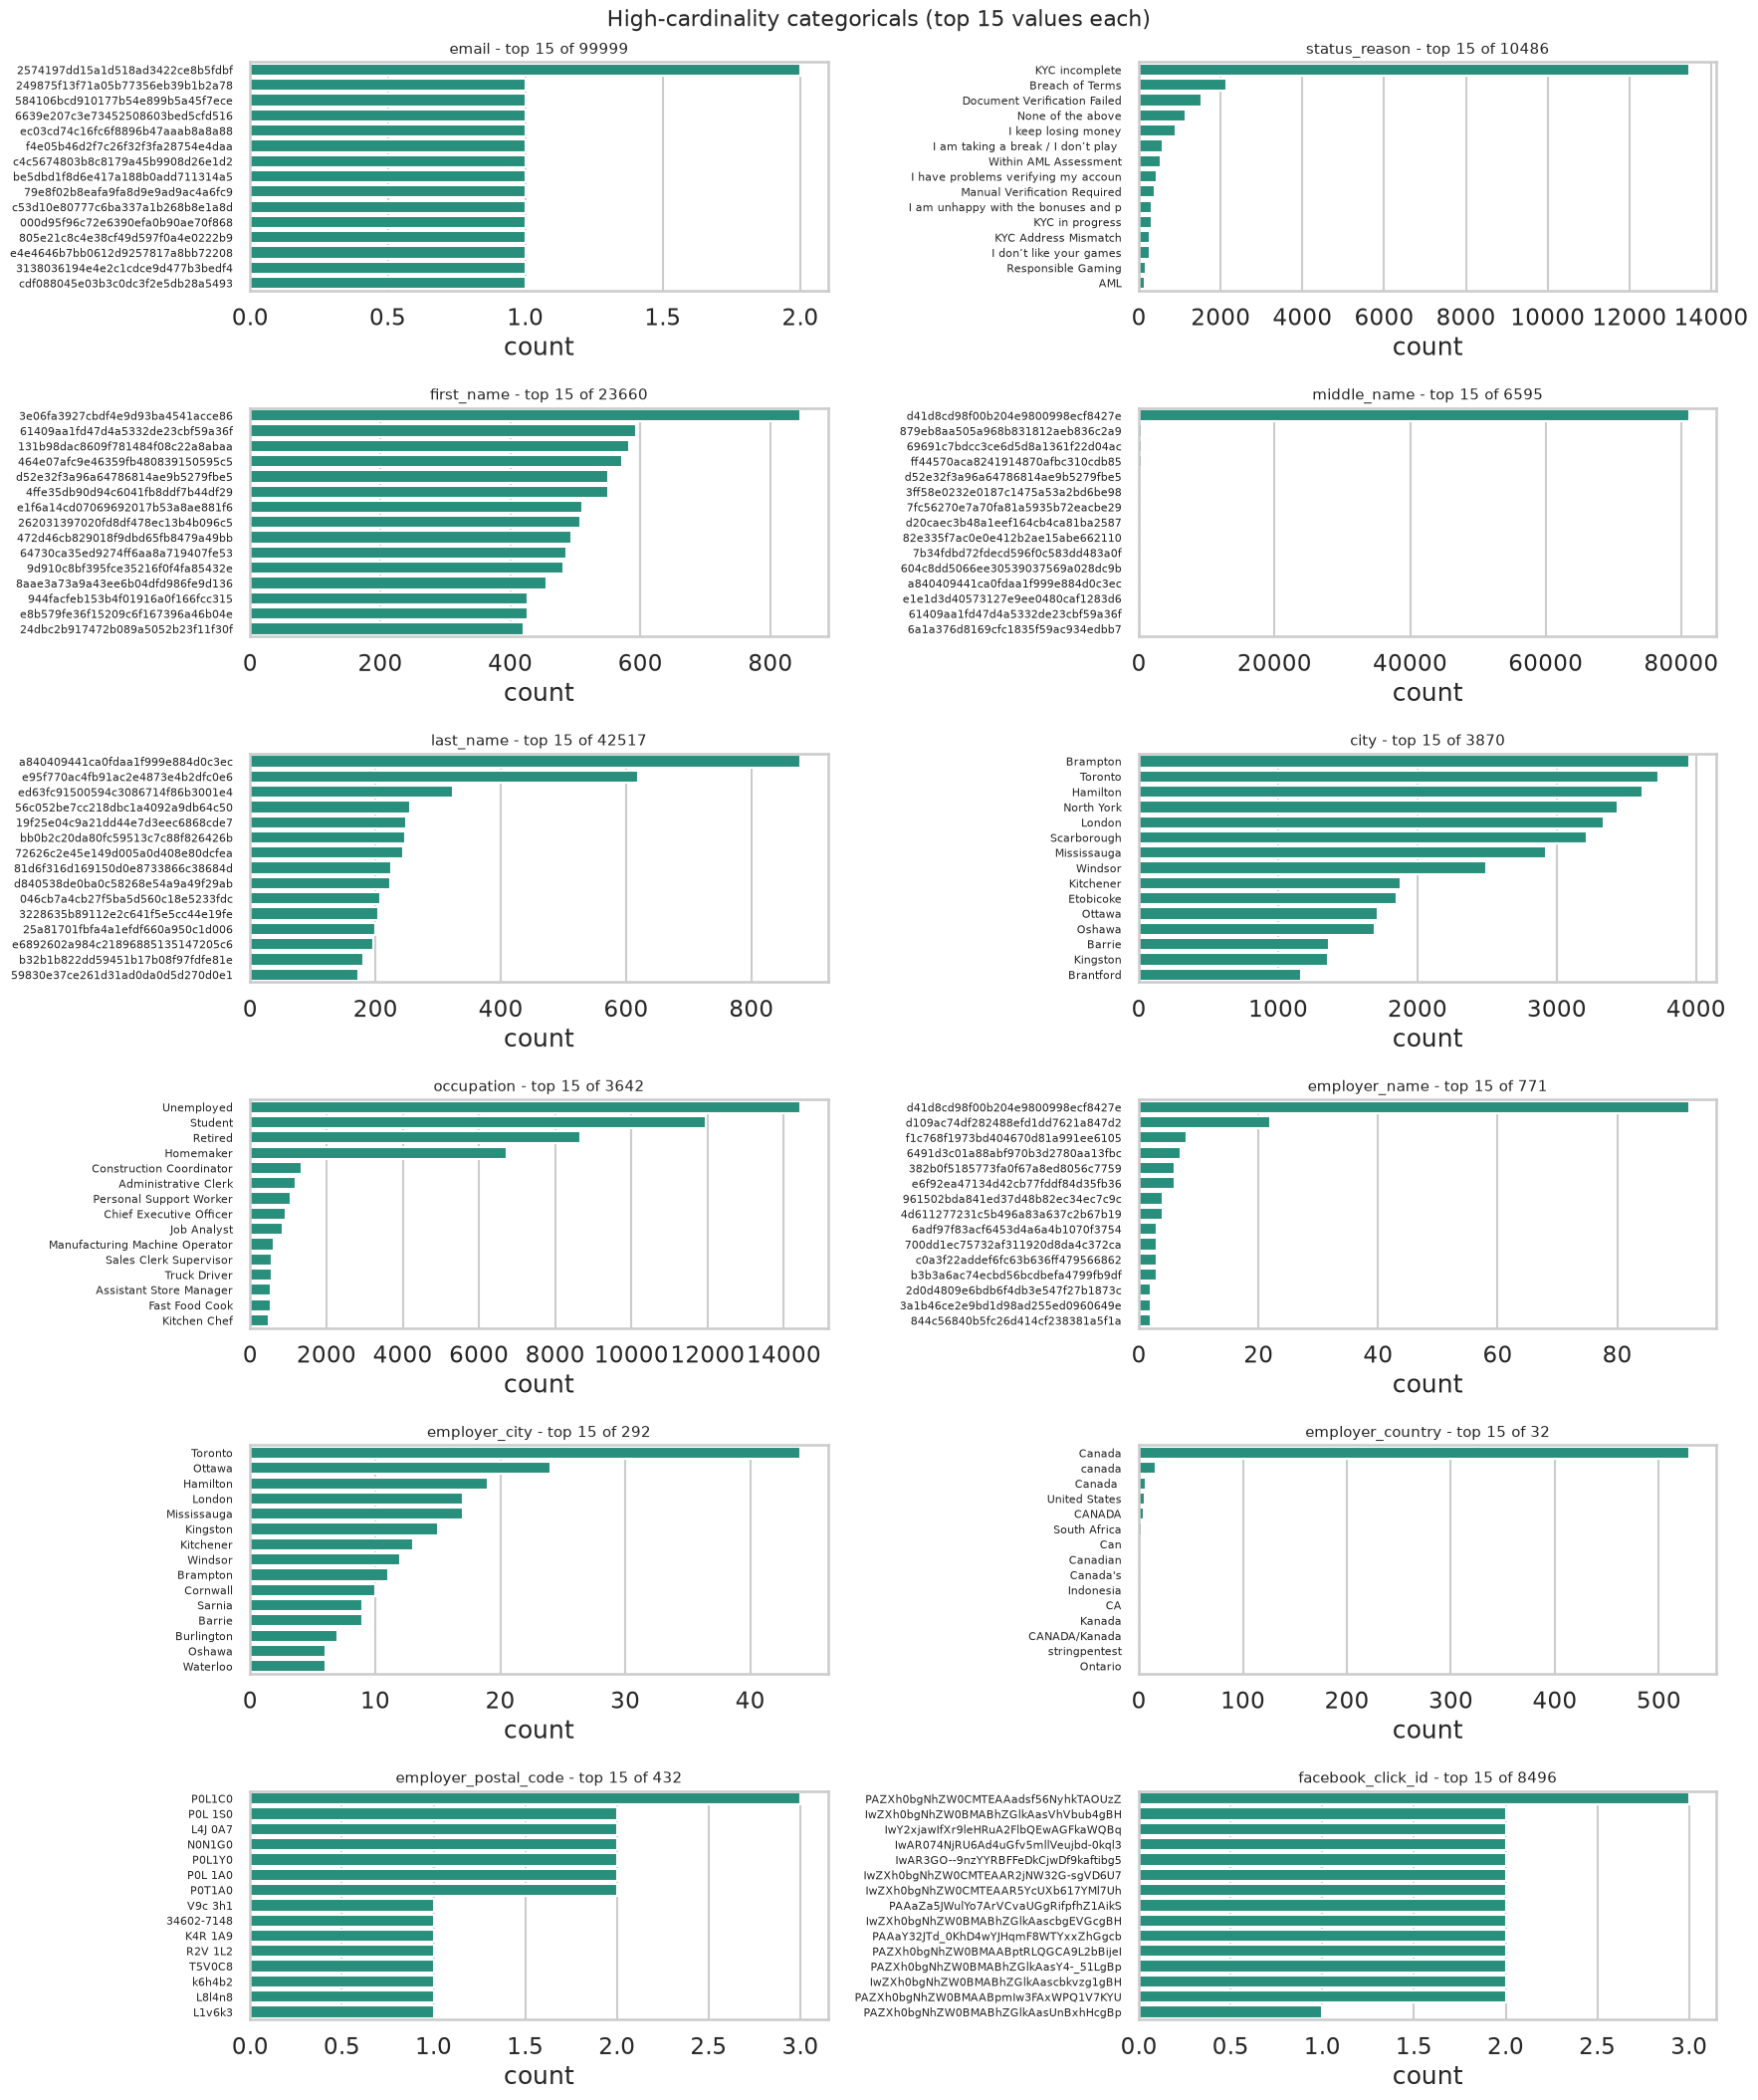


Date column ranges:
    registration_date: 2023-02-17 15:20:10.294000 -> 2025-11-13 07:39:26.364000  (missing 0)
    modified_at: 2023-03-26 05:00:15.598000 -> 2025-11-13 07:39:26.364000  (missing 0)
    closed_at: 2023-05-03 17:16:13.261000 -> 2025-11-13 06:49:24.327000  (missing 82192)
    tc_accepted_date: 2023-02-22 09:35:38.849000 -> 2025-11-13 07:39:26.364000  (missing 0)
    birth_date: 0196-09-13 00:00:00 -> 2020-01-19 00:00:00  (missing 0)
    loaded_at: 2025-06-03 08:46:46 -> 2025-11-13 08:03:42  (missing 0)
    vip_status_updated_at: 2025-01-31 05:56:49.799134 -> 2025-11-13 06:02:07.394000  (missing 99642)
    first_deposit_day: 2023-02-23 00:00:00 -> 2025-11-13 00:00:00  (missing 39933)


[saved] eda_output/datetime_distributions.png


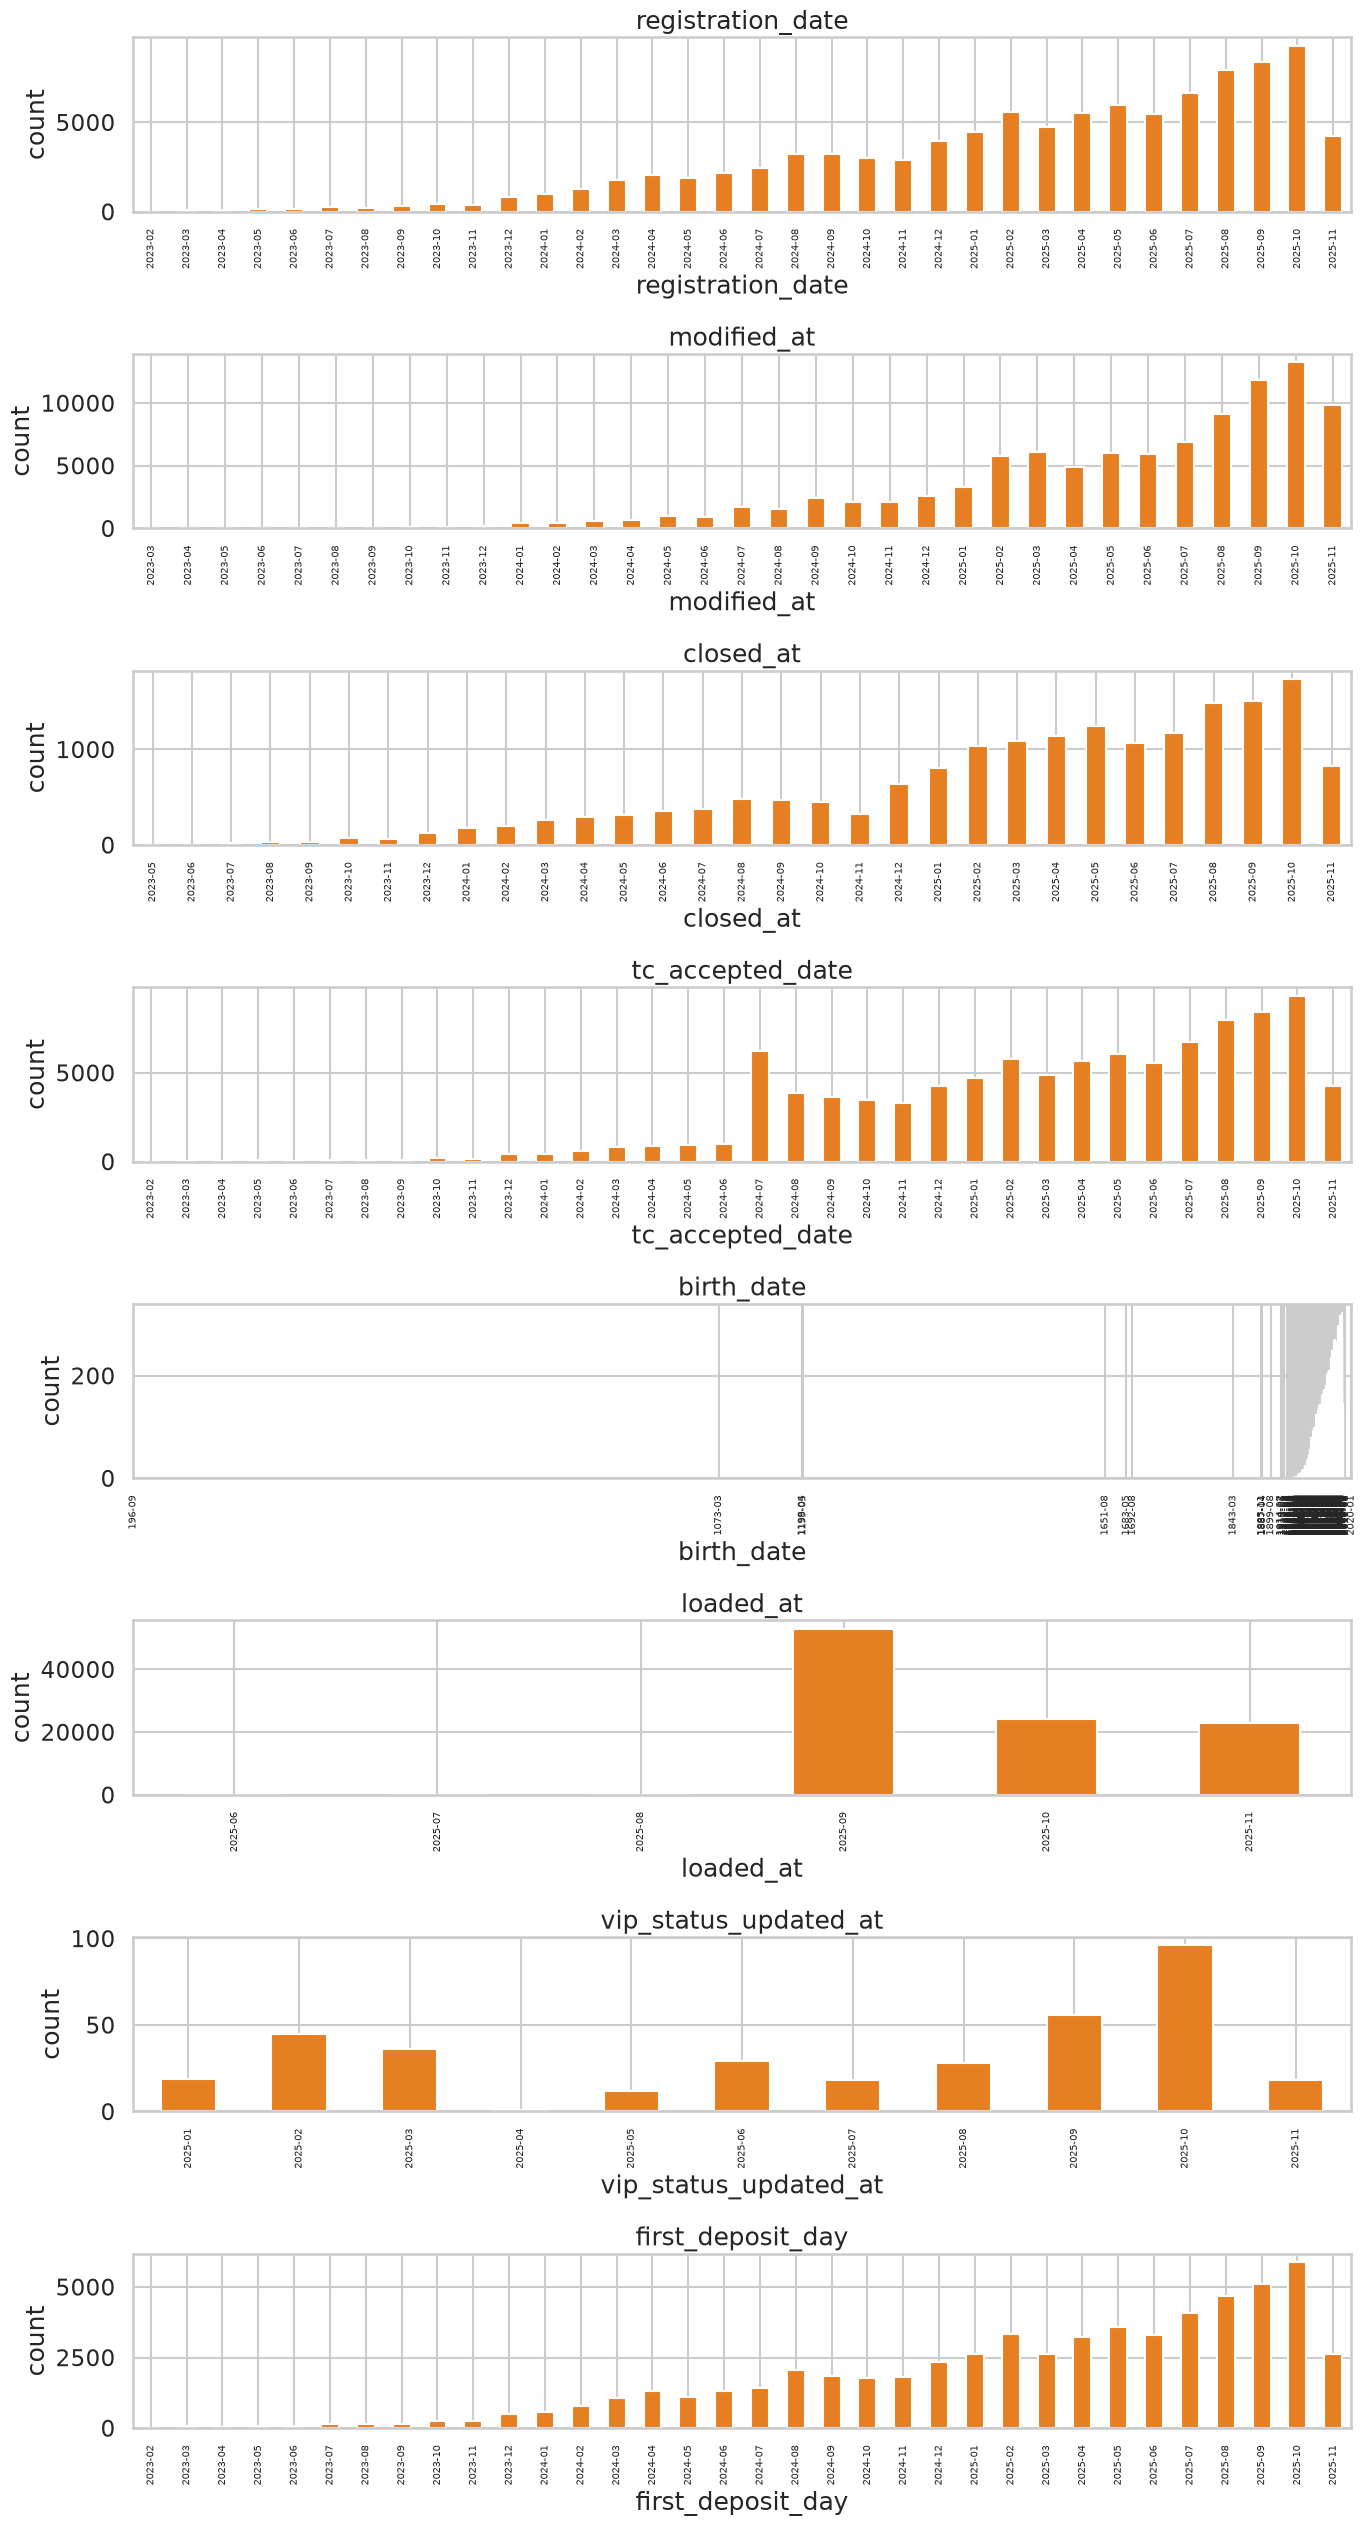

In [7]:
log("=" * 78)
log("6. DISTRIBUTIONS - CATEGORICAL")
log("=" * 78)

high_card_skip = set(numeric_cols) | set(date_cols)
bar_cats = [c for c in categorical_cols
            if 1 < df[c].nunique(dropna=True) <= 25]
log(f"Columns plotted as bar charts (2-25 unique values): {bar_cats}")

ncols = 3
n = len(bar_cats)
nrows = int(np.ceil(n / ncols)) if n else 1
fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 4.2 * nrows))
axes = np.array(axes).ravel()
for i, c in enumerate(bar_cats):
    ax = axes[i]
    vc = df[c].value_counts(dropna=False).head(25)
    labels = [str(v)[:28] for v in vc.index]
    sns.barplot(x=vc.values, y=labels, ax=ax, color="#2980b9")
    ax.set_title(f"{c} ({df[c].nunique(dropna=True)} uniq)", fontsize=11)
    ax.set_xlabel("count")
    ax.tick_params(axis="y", labelsize=8)
    for p in ax.patches:
        w = p.get_width()
        ax.text(w + w * 0.01, p.get_y() + p.get_height() / 2,
                f"{int(w)}", va="center", fontsize=7)
if n:
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")
    fig.suptitle("Categorical variable distributions", fontsize=16)
    fig.tight_layout()
    save(fig, "categorical_distributions.png")

# top-N for high cardinality categoricals
high_card = [c for c in categorical_cols if df[c].nunique(dropna=True) > 25]
log("")
log(f"High-cardinality categorical columns ({len(high_card)}):")
for c in high_card:
    log(f"    {c}: {df[c].nunique(dropna=True)} unique values, "
        f"{df[c].isna().sum()} missing")

if high_card:
    ncols = 2
    n = min(len(high_card), 12)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(9 * ncols, 3.6 * nrows))
    axes = np.array(axes).ravel()
    for i, c in enumerate(high_card[:n]):
        ax = axes[i]
        vc = df[c].value_counts().head(15)
        labels = [str(v)[:35] for v in vc.index]
        sns.barplot(x=vc.values, y=labels, ax=ax, color="#16a085")
        ax.set_title(f"{c} - top 15 of {df[c].nunique()}", fontsize=11)
        ax.tick_params(axis="y", labelsize=8)
        ax.set_xlabel("count")
    for j in range(i + 1, len(axes)):
        axes[j].axis("off")
    fig.suptitle("High-cardinality categoricals (top 15 values each)", fontsize=16)
    fig.tight_layout()
    save(fig, "high_cardinality_top15.png")

# date distributions
if date_cols:
    log("")
    log("Date column ranges:")
    for c in date_cols:
        s = df[c].dropna()
        log(f"    {c}: {s.min()} -> {s.max()}  (missing {df[c].isna().sum()})")
    fig, axes = plt.subplots(len(date_cols), 1,
                             figsize=(14, 3.2 * len(date_cols)), squeeze=False)
    for ax, c in zip(axes.ravel(), date_cols):
        s = df[c].dropna()
        try:
            s.dt.to_period("M").value_counts().sort_index().plot(kind="bar", ax=ax,
                                                                 color="#e67e22")
            ax.set_title(c)
            ax.set_ylabel("count")
            ax.tick_params(axis="x", labelrotation=90, labelsize=7)
        except Exception as e:
            ax.set_title(f"{c} (plot failed: {e})")
    fig.tight_layout()
    save(fig, "datetime_distributions.png")


## 7. Correlations


7. CORRELATIONS
Excluded from correlation (100% missing): ['ad_group', 'ad_set', 'marketing_creative', 'marketing_keyword', 'marketing_network', 'marketing_click_date', 'marketing_location']
Pearson correlation matrix:
                         player_id  phone_number  employer_phone_number  referrer_player_id  vip_level  ad_campaign_id  ad_group_id  ad_keyword_id  max_profit_segment_rank  total_deposits  total_withdrawals  total_bets  total_wins  total_logins
player_id                    1.000        -0.006                 -0.030               0.725        NaN          -0.085       -0.085         -0.083                   -0.261          -0.135             -0.129      -0.120      -0.119        -0.256
phone_number                -0.006         1.000                  0.175               0.016        NaN           0.009        0.009          0.008                    0.013           0.006              0.005       0.008       0.007        -0.001
employer_phone_number       -0.030         0.

[saved] eda_output/correlation_heatmap.png


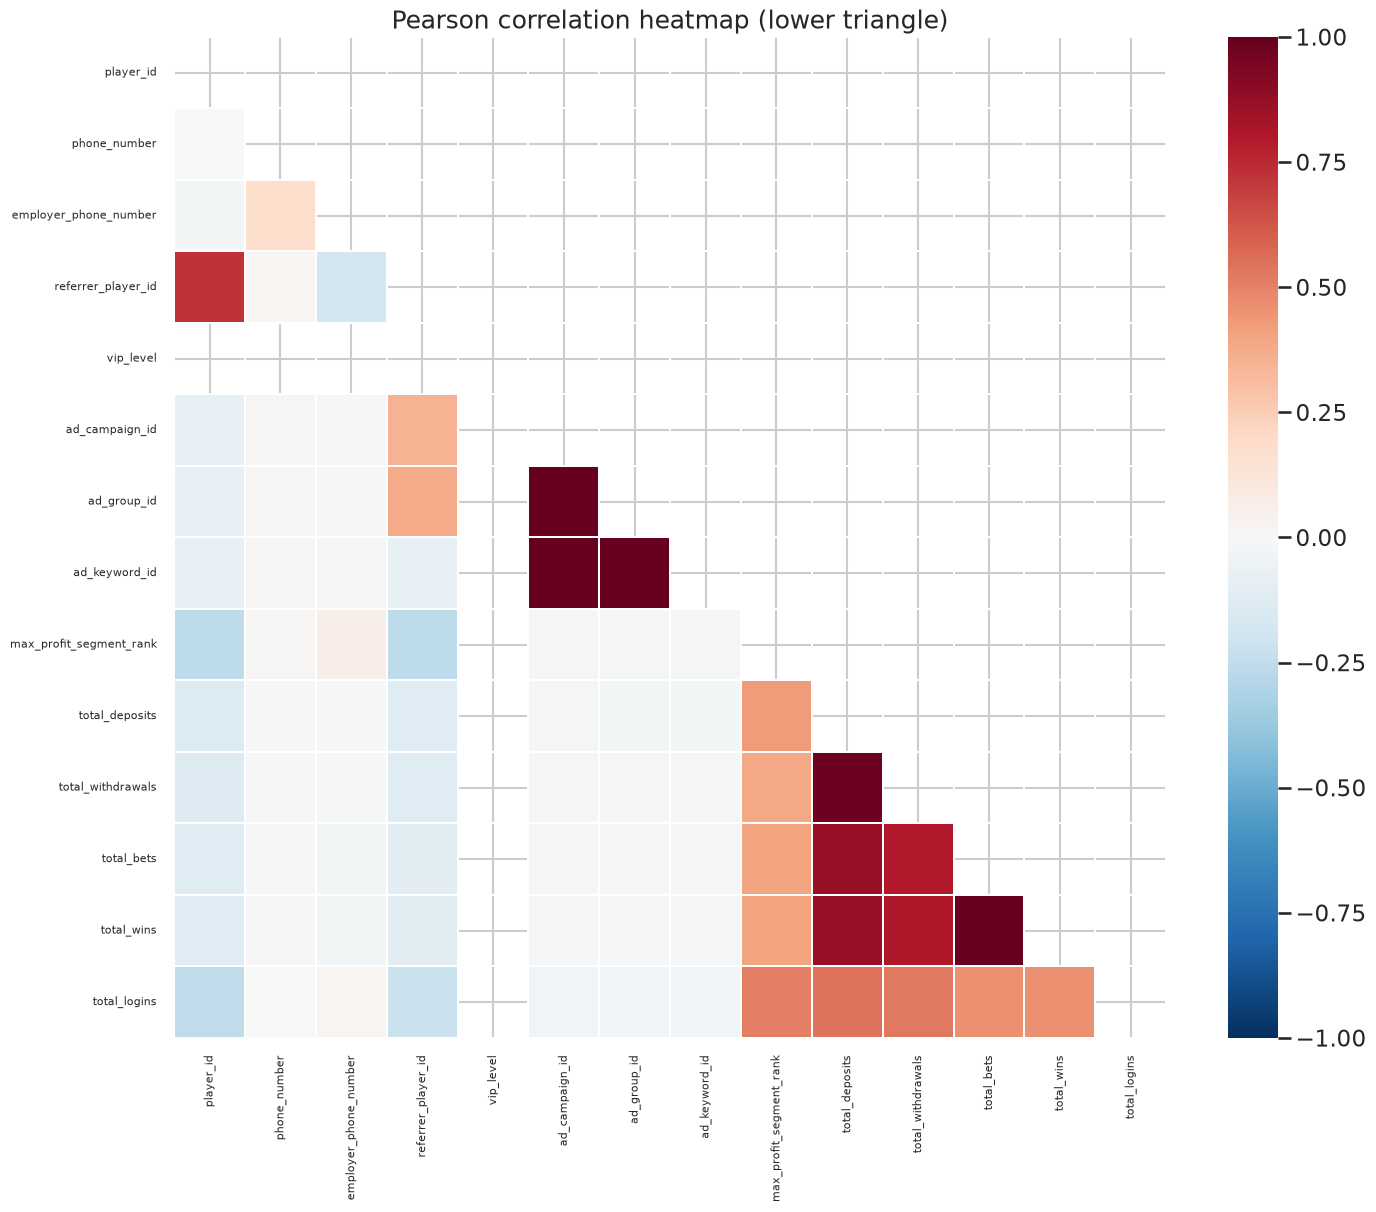

[saved] eda_output/correlation_heatmap_spearman.png


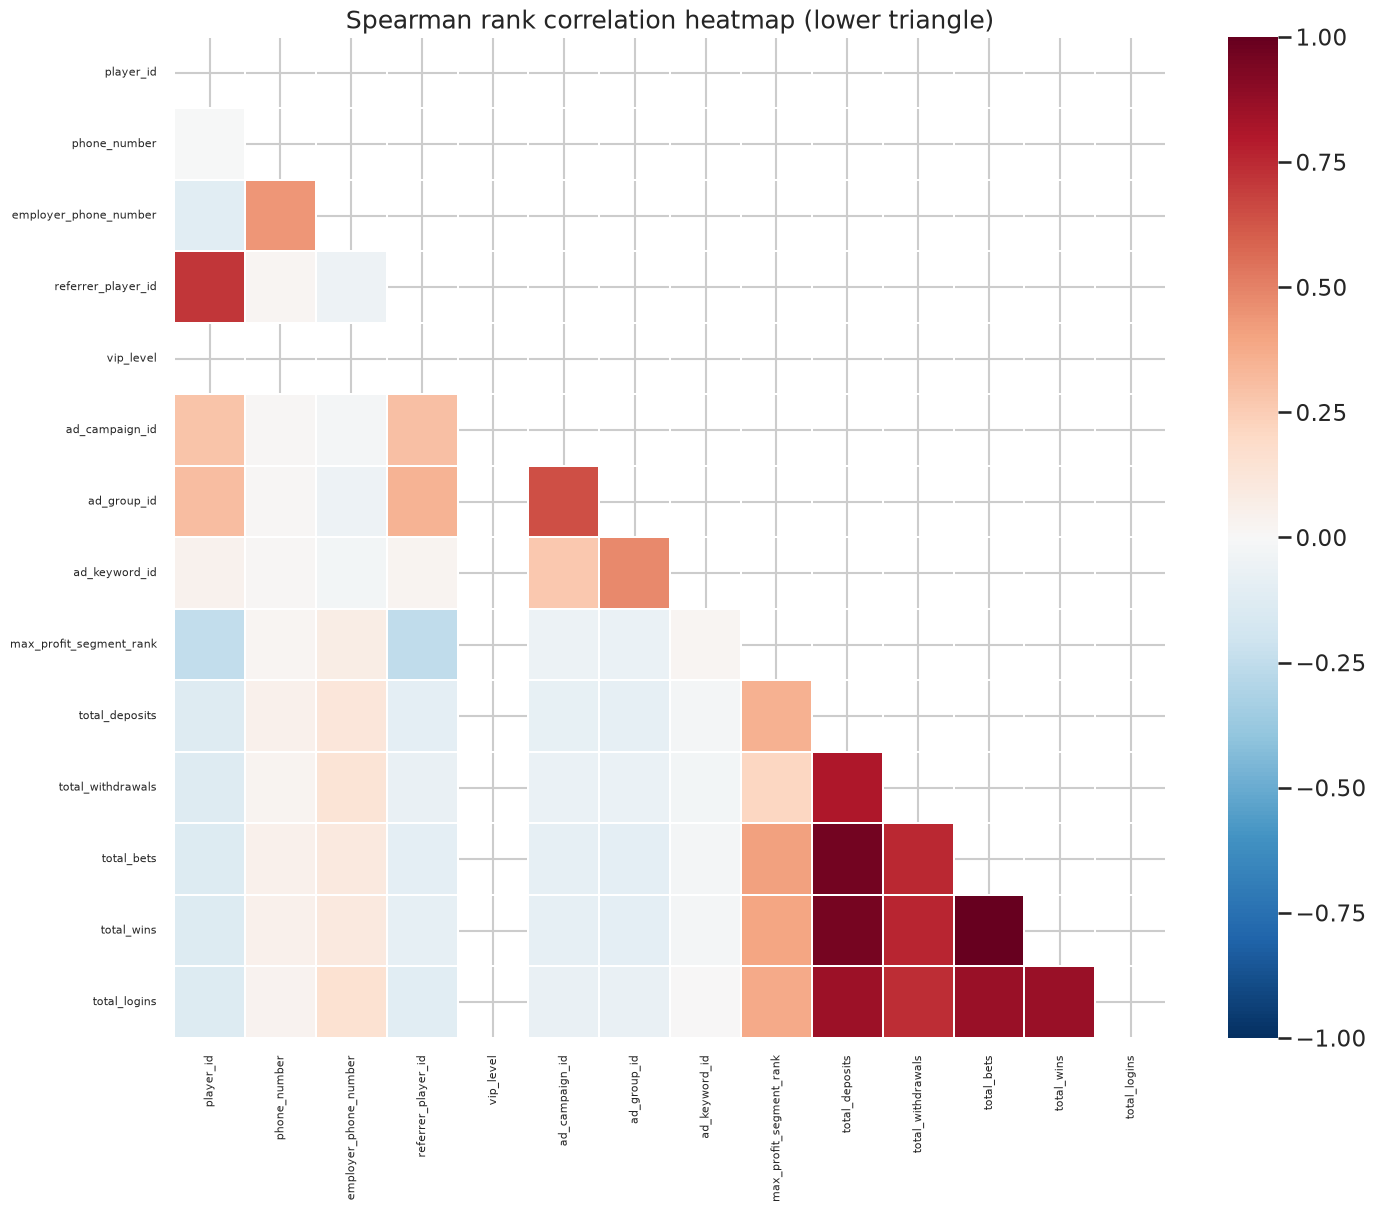

[saved] eda_output/correlation_scatters.png


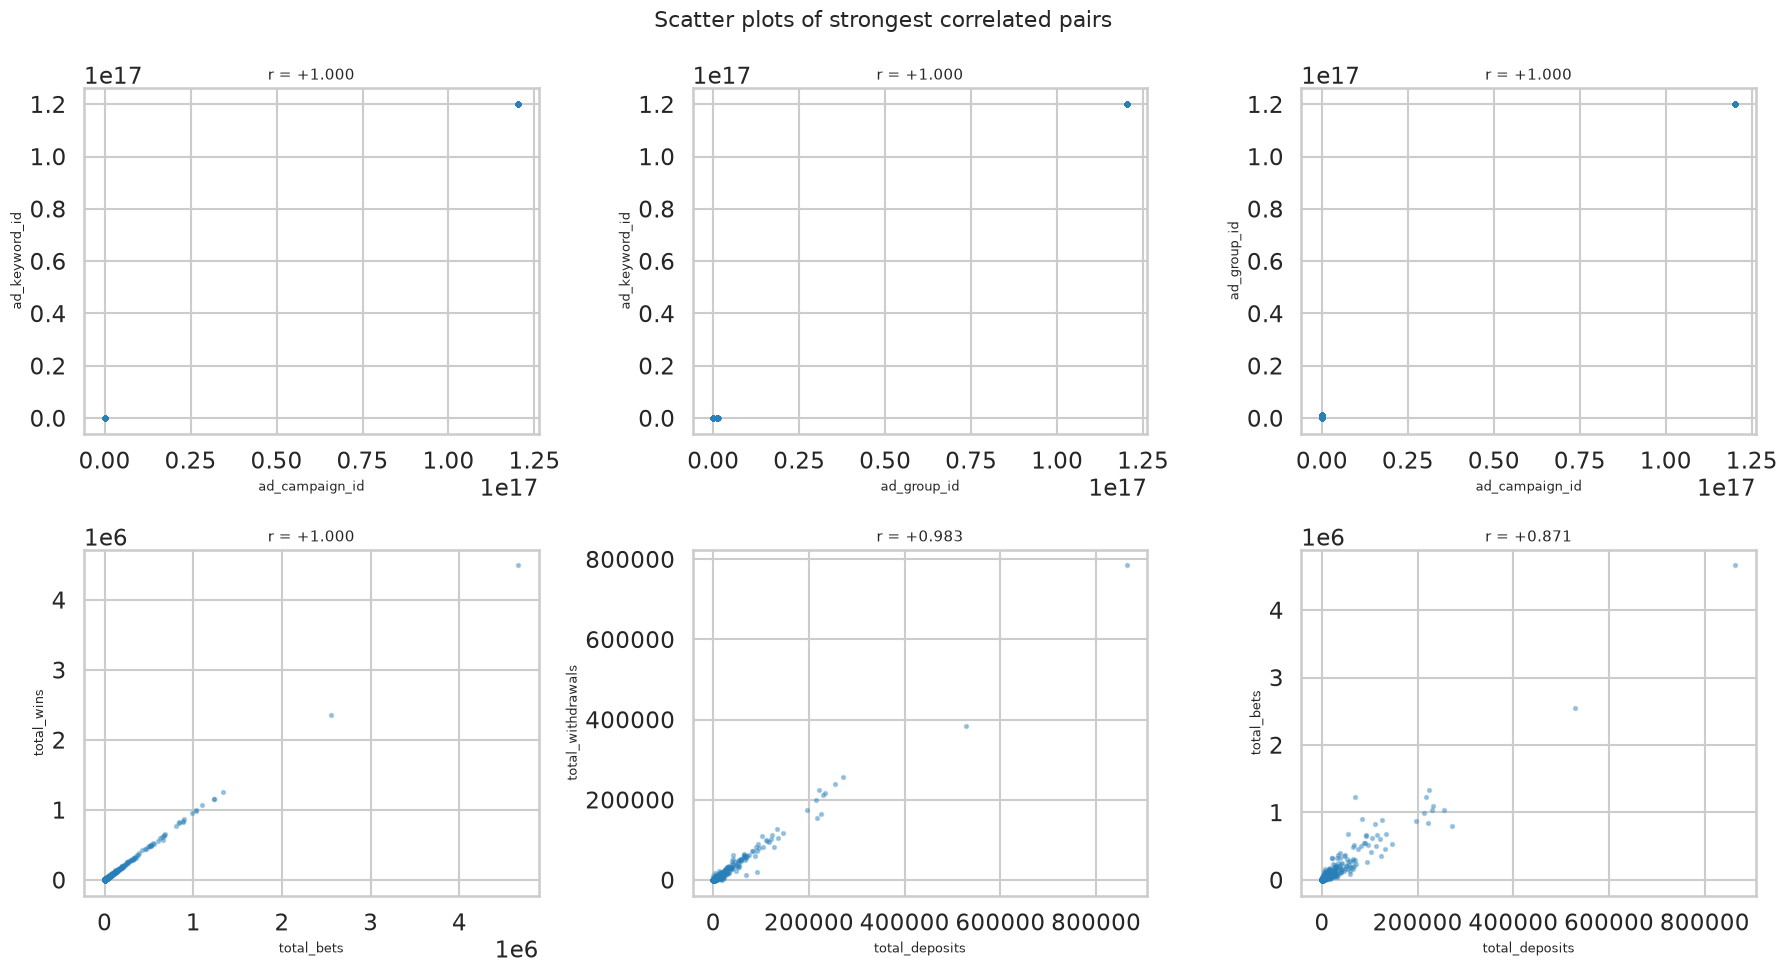

In [8]:
log("")
log("=" * 78)
log("7. CORRELATIONS")
log("=" * 78)

corr = df[numeric_cols].corr(method="pearson")
all_missing = [c for c in numeric_cols if df[c].notna().sum() == 0]
if all_missing:
    log(f"Excluded from correlation (100% missing): {all_missing}")
    corr = corr.drop(index=all_missing, columns=all_missing, errors="ignore")
log("Pearson correlation matrix:")
log(corr.round(3).to_string())
log("")

# strong pairs
pairs = []
cols = list(corr.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr.iloc[i, j]
        if pd.notna(r):
            pairs.append((cols[i], cols[j], r))
pairs.sort(key=lambda t: abs(t[2]), reverse=True)
log("Top 20 strongest |correlations|:")
for a, b, r in pairs[:20]:
    log(f"    {a} <-> {b}: {r:+.3f}")
log("")
log("Moderate/strong correlations (|r| >= 0.5):")
strong = [(a, b, r) for a, b, r in pairs if abs(r) >= 0.5]
if strong:
    for a, b, r in strong:
        log(f"    {a} <-> {b}: {r:+.3f}")
else:
    log("    (none)")
log("")

# heatmap
fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=len(numeric_cols) <= 20, fmt=".2f",
            linewidths=0.3, ax=ax, annot_kws={"size": 7})
ax.set_title("Pearson correlation heatmap (lower triangle)")
ax.tick_params(labelsize=8)
save(fig, "correlation_heatmap.png")

spearman = df[corr.columns].corr(method="spearman")
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(spearman, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.3, ax=ax)
ax.set_title("Spearman rank correlation heatmap (lower triangle)")
ax.tick_params(labelsize=8)
save(fig, "correlation_heatmap_spearman.png")

# scatter plots of top correlated pairs
top_pairs = pairs[:6]
if top_pairs:
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()
    for ax, (a, b, r) in zip(axes, top_pairs):
        sub = df[[a, b]].dropna()
        if len(sub) > 3000:
            sub = sub.sample(3000, random_state=42)
        ax.scatter(sub[a], sub[b], s=6, alpha=0.35, color="#2980b9")
        ax.set_xlabel(a, fontsize=9)
        ax.set_ylabel(b, fontsize=9)
        ax.set_title(f"r = {r:+.3f}", fontsize=11)
    for ax in axes[len(top_pairs):]:
        ax.axis("off")
    fig.suptitle("Scatter plots of strongest correlated pairs", fontsize=16)
    fig.tight_layout()
    save(fig, "correlation_scatters.png")


## 8. Additional notes & save report

In [9]:
log("")
log("=" * 78)
log("8. ADDITIONAL NOTES")
log("=" * 78)
log(f"Duplicate rows: {df.duplicated().sum()}")
if "player_id" in df.columns:
    log(f"player_id unique: {df['player_id'].nunique()} / {n_rows} "
        f"(duplicates: {df['player_id'].duplicated().sum()})")
log(f"Numeric columns: {len(numeric_cols)}, Categorical: {len(categorical_cols)}, "
    f"Datetime: {len(date_cols)}, Boolean: {len(bool_cols)}")

report_path = os.path.join(OUT, "eda_report.txt")
with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(lines))
print(f"\nReport written to {report_path}")



8. ADDITIONAL NOTES


Duplicate rows: 0
player_id unique: 100000 / 100000 (duplicates: 0)
Numeric columns: 21, Categorical: 45, Datetime: 8, Boolean: 3

Report written to eda_output/eda_report.txt
